# Practical task: Modelling hotel cancellations

# Task

The aim of this task is to create a model or set of models which could be used to predict whether a customer is going to cancel a hotel booking.

To pass, you should include, at least:
* Some exploratory data analysis to justify features used in the model
* At least two different binary classification models
* Markdown boxes to compare the models and to explain your process and observations

For a full explanation of the marking criteria, see the documents in Integral.

<a id='intro'></a>
# Introduction

This data set contains information on 119,390 hotel bookings between July 2015 and August 2017. Each observation represents a hotel booking.

The data for two hotels is given. Both hotels are located in Portugal: the Resort Hotel is in the region of the Algarve and the City Hotel is in the city of Lisbon. A variety of categorical and numeric features are provided, including whether the book was cancelled.

Hotel management would find it useful to be able to predict whether a booking is likely to be cancelled.

<a id='import'></a>
# Importing libraries and data

<a id='libraries'></a>
## Importing the libraries

In [1]:
# pandas for data analysis
import pandas as pd

# seaborn for visualisation
import seaborn as sns
sns.set_context("talk")

# seaborn has some unhelpful warnings at the moment
import warnings
warnings.filterwarnings("ignore", module="seaborn")

# Import functions from sklearn for building the model, training-testing split, visualising the model and metrics 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Function to draw the model
def plot_decision_tree(tree_model):
    fig, ax = plt.subplots(figsize=(20,8))
    plot_tree(tree_model,  
        filled=True, 
        impurity=False, 
        feature_names=input_features, 
        class_names=["No","Yes"], 
        proportion=True, 
        ax=ax)
    plt.show()

<a id='data'></a>
## Importing the data

In [2]:
hotel_data = pd.read_csv('../input/hotel-bookings/bookings_2025.csv')
hotel_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,is_canceled
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,0,0,3,0,0,0.00,0
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,0,0,4,0,0,0.00,0
2,Resort Hotel,BB,Direct,7,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
3,Resort Hotel,BB,Corporate,13,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
4,Resort Hotel,BB,Online TA,14,0,2,2,0.0,0,0,0,0,0,0,1,98.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,BB,Offline TA/TO,23,2,5,2,0.0,0,0,0,0,0,0,0,96.14,0
119386,City Hotel,BB,Online TA,102,2,5,3,0.0,0,0,0,0,0,0,2,225.43,0
119387,City Hotel,BB,Online TA,34,2,5,2,0.0,0,0,0,0,0,0,4,157.71,0
119388,City Hotel,BB,Online TA,109,2,5,2,0.0,0,0,0,0,0,0,0,104.40,0


In [3]:
hotel_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   meal                            119390 non-null  object 
 2   market_segment                  119390 non-null  object 
 3   lead_time                       119390 non-null  int64  
 4   stays_in_weekend_nights         119390 non-null  int64  
 5   stays_in_week_nights            119390 non-null  int64  
 6   adults                          119390 non-null  int64  
 7   children                        119386 non-null  float64
 8   babies                          119390 non-null  int64  
 9   is_repeated_guest               119390 non-null  int64  
 10  previous_cancellations          119390 non-null  int64  
 11  previous_bookings_not_canceled  119390 non-null  int64  
 12  booking_changes 

<a id='pre'></a>
# Preparing the data and exploratory data analysis


**Slicing to focus on a specific type of hotel:**

The two hotel types likely to differ from each other as city hotels likely to have more guests for short stay business travelers with volatile schedules compared to resort hotels more likely to be having long stay leisure guests whose holiday bookings are usually more stable.

In [4]:
# To replace 0s and 1s with words to make it easier to follow.
hotel_data['is_canceled'] = hotel_data['is_canceled'].replace({0: 'No', 1: 'Yes'})

resort_hotel_data = hotel_data[hotel_data['hotel'] == 'Resort Hotel'].copy()
city_hotel_data = hotel_data[hotel_data['hotel'] == 'City Hotel'].copy()
display(pd.crosstab(city_hotel_data['hotel'], city_hotel_data['is_canceled'], normalize='index').round(3))
display(pd.crosstab(resort_hotel_data['hotel'], resort_hotel_data['is_canceled'], normalize='index').round(3))
city_hotel_data.shape


is_canceled,No,Yes
hotel,,
City Hotel,0.583,0.417


is_canceled,No,Yes
hotel,,
Resort Hotel,0.722,0.278


(79330, 17)

The results show that City Hotels have a significantly higher cancellation rate (41.7%) compared to Resort Hotels (27.8%). This supports my theory that city hotel guests often have more unpredictable schedules. Because these two hotel types behave so differently, mixing them together might confuse the model. I have decided to focus only on City Hotel bookings to make my predictions more specific and accurate.

In [5]:
# Creating a new 'total_stay' by adding the two night types together to only have one category to deal with for each booking.
city_hotel_data['total_stay'] = city_hotel_data['stays_in_weekend_nights'] + city_hotel_data['stays_in_week_nights']

"total_stay" was created by combining weekend and weeknights to improve the models future set as its much easier to deal with a single variable for days stayed by the guests.

**Deciding possible features that may be used in modelling:**

To build an effective model we need to observe which features listed here are most possible to be closely linked with cancellations.

Observation 1:
It is likely that further in advance when someone books they are more likely to cancel their booking as a lot more could change that possibly make them change their mind over larger period of time between them booking and arriving at the hotel.

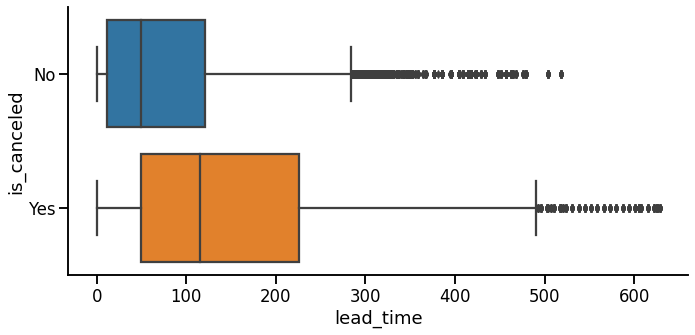

In [6]:

sns.catplot(data=city_hotel_data, kind='box', x='lead_time', y='is_canceled', orient='h', aspect=2);

1. The Average (Median): Since the average "lead_time" for bookings to be canceled is significantly higher for "Yes" (which is around 110 days compared to approximately 50 days for the case "No") there is sufficient evidence to suggest that bookings made further in advance are more likely to be cancelled.
   
2. Anomalies: There are plenty of anomalies for both cases for example for "No" there are 2 bookings which had a "lead_time" for more than 500 days yet they didn't cancel which shows that if we were to just assume that further in advance the booking made they are most likely going to cancel we could potentially wrongly identify loyal customers which could cause us problems if we were to overbook their rooms.

3. The Interquartile Range (IQR): The larger IQR for cancelled bookings shows that there is more uncertainty in how far in advance people book that cancels, which makes it a more difficult category to predict what will happen than those who do show up.

Observation 2: I believe that how the booking was made could have a significant effect on whether they will cancel or not for example someone that booked through corporate are usually more "stable". Since if a company is paying for a room for a business trip the employee is very likely to show up meaning that its likely that these bookings will have lower cancellation rates than other booking types like "Online TA" bookings.

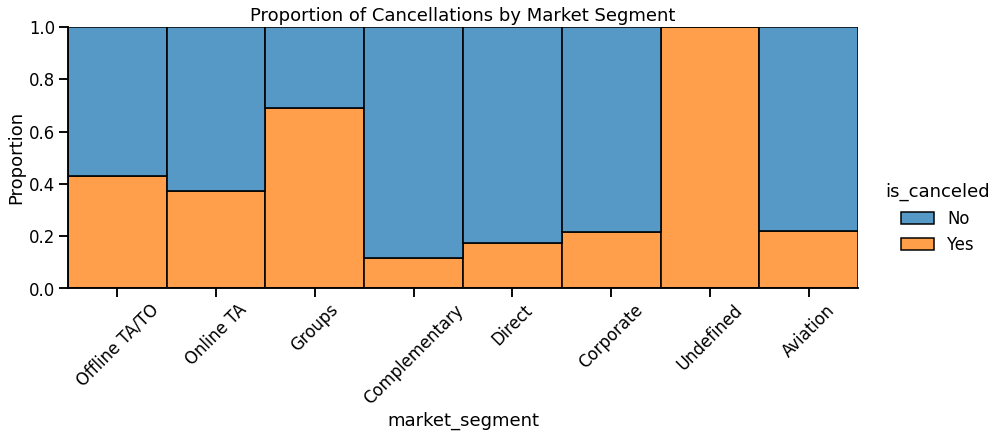

In [7]:
sns.displot(data=city_hotel_data, x='market_segment', hue='is_canceled', 
            multiple='fill', stat='proportion', aspect=2.5)
plt.xticks(rotation=45)
plt.title('Proportion of Cancellations by Market Segment')
plt.show()

The chart clearly shows that "Groups" and "Online TA" have much higher cancellation proportions compared to "Corporate" and "Direct". This supports my decision to use market_segment as a feature in the model.

In [8]:
features = ['lead_time', 'adr', 'total_stay', 'total_of_special_requests']
city_hotel_data.groupby('is_canceled')[features].mean().round(2)

,lead_time,adr,total_stay,total_of_special_requests
is_canceled,,,,
No,80.70,105.75,2.92,0.74
Yes,150.28,104.69,3.05,0.28


Cancelled bookings have significantly higher average lead_time. Although adr, total_stay and total_of_special_requests show smaller differences, they may still add value when combined in the model.

**Justifications for the features that I decided to use in the modelling:**

From the exploratory data analysis above, I chose the following features because they showed clear relationships with cancellations:

1. **lead_time**: Much higher average and median for cancelled bookings
2. **market_segment**: Strong differences between high-risk (Groups, Online TA) and low-risk (Corporate, Direct) bookings
3. **total_stay**: Created to combine weekend and week nights into one feature
4. **adr**: To check if higher room prices affect cancellation decisions
5. **total_of_special_requests**: Guests with special requests may be less likely to cancel

<a id='model'></a>
# Building models

**Model 1 with only numerical categories (lead_time, market_segment, total_stay, adr):**

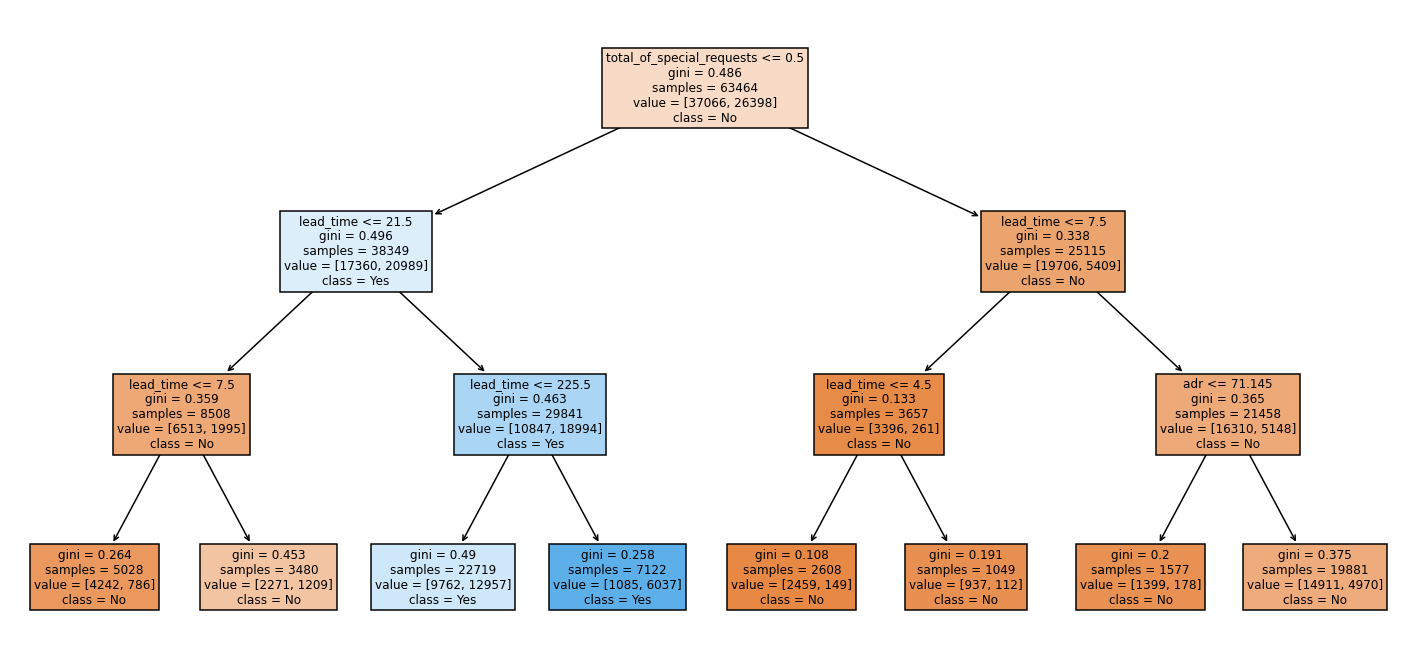

DecisionTreeClassifier(max_depth=10)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

features = ['lead_time', 'adr', 'total_stay', 'total_of_special_requests']
X = city_hotel_data[features]
y = city_hotel_data['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

model_1 = DecisionTreeClassifier(max_depth=3)
model_1.fit(X_train, y_train)

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25,12))

plot_tree(model_1, 
          feature_names=features, 
          class_names=['No', 'Yes'], 
          filled=True, 
          fontsize=12)

plt.show()

model_2 = DecisionTreeClassifier(max_depth=10)
model_2.fit(X_train, y_train)

I have only displayed the flowchart for Model 1 (Depth 3) because it is easy to read and shows the main rules the model uses to make decisions. I didn't show the tree for Model 2 (Depth 10) because it is much more complex with hundreds of branches, which makes the diagram too small to actually see or understand.


In [10]:
# Model 1 predictions
predictions_1 = model_1.predict(X_test)

# Model 2 predictions
predictions_2 = model_2.predict(X_test)

In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix

score_1 = accuracy_score(y_test, predictions_1)
score_2 = accuracy_score(y_test, predictions_2)

print("Simple Model Accuracy:", round(score_1, 5))

print("Complex Model Accuracy:", round(score_2, 5))

cm = confusion_matrix(y_test, predictions_2)

print("Confusion Matrix")
print("             Pred: NO    Pred: YES")
print("Actual: NO  ", cm[0,0], "      ", cm[0,1] )
print("Actual: YES ", cm[1,0], "      ", cm[1,1])


Simple Model Accuracy: 0.71196
Complex Model Accuracy: 0.76024
Confusion Matrix
             Pred: NO    Pred: YES
Actual: NO   7515        1647
Actual: YES  2157        4547


Complex model likely have a higher accuracy because of the higher depth which model can use to make better predictions (10 vs 3)


**Model 2 with market_segment category**

To make this model even better we can encode market_segment to the numerical categories to improve the accuracy of our model.

In [12]:
city_hotel_data['segment_encoded'] = city_hotel_data['market_segment'].astype('category').cat.codes

features_final = ['lead_time', 'adr', 'total_stay', 'total_of_special_requests', 'segment_encoded']
X_final = city_hotel_data[features_final]
y_final = city_hotel_data['is_canceled']

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_final, y_final, train_size=0.8, random_state=1)

model_3 = DecisionTreeClassifier(max_depth=10)
model_3.fit(X_train_f, y_train_f)
predictions_3 = model_3.predict(X_test_f)

from sklearn.metrics import accuracy_score, confusion_matrix

print("FINAL MODEL COMPARISON")
score_2 = accuracy_score(y_test, predictions_2)
print("Model 1 (Numerical Only) Accuracy:", round(score_2, 5))
print("Model 2 (With Market Segment) Accuracy:", round(accuracy_score(y_test_f, predictions_3), 5))

print("Final Confusion Matrix")
cm_final = confusion_matrix(y_test_f, predictions_3)
print("             Pred: NO    Pred: YES")
print("Actual: NO  ", cm_final[0,0], "      ", cm_final[0,1] )
print("Actual: YES ", cm_final[1,0], "      ", cm_final[1,1])

FINAL MODEL COMPARISON
Model 1 (Numerical Only) Accuracy: 0.76024
Model 2 (With Market Segment) Accuracy: 0.7731
Final Confusion Matrix
             Pred: NO    Pred: YES
Actual: NO   7683        1479
Actual: YES  2121        4583


# Conclusions

(the numerical values for fails and successes changes slightly each time you run the code I just used the values that were on the confusion matrices during that time, I believe this is happening because the random samples taken from the whole list of bookings are changing each time which also gives different accuracy because the model may be better at identifying certain pattern than others when looking at features of a specific booking.)
_________________________________________________________________________________
**For the model 1 with only numerical values:**

**Successes:**

**True negatives(7514):** The model correctly identified 7517 bookings where guests showed up.

**True positive (4546):** The model correctly identified 4549 cancellations. This is the most valuable one as this allows hotel to put these rooms back in the market for others to rent.

**Fails:**

**False positives (1648):** The model predicted a cancellation but guests showed up meaning if hotel manager overbooks the hotel based on the model which means there will be quests showing up with no room available. This leads to costs as a compensation and also damaged reputation so potential loss of future customers.

**False negatives (2158):** This is lost revenue as model predicted they would show up but they actually cancelled so rooms were empty because model couldnt predict it.

_________________________________________________________________________________
**Comparing it with the model 2 with market_segment embedded:**

**Successes:**

**True negatives(7514 to 7682):** The model correctly identified 168 more bookings where guests showed up, which means we could have available room for more customers when they showed up as we didnt put their rented rooms on the market again which is a slight improvement.

**True positive (4546 to 4585):** The model correctly identified 39 more cancellations. So 39 more rooms could be put on the market again which means more revenue for the company when compared to previous model.

**Fails:**

**False positives (1648 to 1482):** The model incorrectly predicted 166 less guests who actually showed up after predicted to be cancelled. This is probably the most valuable change in two models as we are essentially risking the reputation of the company when we assume someone is going to cancel their bookings, as there is a chance they may arrive. By decreasing the chance of getting these incorrectly we will be less likely to be in a difficult position where we have no available rooms.

**False negatives (2158):** This is lost revenue as model predicted they would show up but they actually cancelled so rooms were empty because model couldnt predict it.
_________________________________________________________________________________
**Why second model is probably better:**

Even though a 1.26% increase in accuracy seems small, it makes the model much more robust. By using a variety of features like market segments, we aren't just guessing based on the price anymore but we are also using the actual categories that I found were high risk during my data analysis. This helps the hotel manager make safer decisions about their rooms.
_________________________________________________________________________________
**Should we use the model to predict the cancellations in real life situation?**

In a real hotel, I would recommend using this model as a support tool rather than letting it make all the decisions automatically. The manager can use the models prediction for high risk of cancellations to take any action. Even though over-booking the rooms of the guests would not be ethical (as even though we are 77.3% likely to be correct we might still be wrong), manager can still use these to decide who to call for a deposit or who to send extra confirmation emails to.
